# Formative 3: Probability Distributions, Bayes and Gradient Descent
All logic lives in small modules (`em.py`, `bayes.py`, `gradient_descent.py`, `plots.py`, `utils.py`); this notebook only calls them (DRY).

| Part | Topic | Module |
|---|---|---|
| 1 | Gaussian mixture with EM, from scratch | `em.py` |
| 2 | Bayes' theorem on IMDb reviews (basic Python) | `bayes.py` |
| 3 | Gradient descent by hand | `gradient_descent.py` (checked against it) |
| 4 | Gradient descent in code with SciPy | `gradient_descent.py`, `plots.py` |

## Part 1: EM on a mixture of two Gaussians
**Data.** `GaltonFamilies.csv`: heights of fathers and their children. Parents are repeated once per child in the raw file, so we keep **one row per family** (205 fathers) to avoid counting the same father many times. We pool fathers and children (1,139 heights) and **discard the labels**, so the model sees one unlabeled pile.

**Model.** $p(x)=\pi_1\mathcal N(x|\mu_1,\sigma_1^2)+\pi_2\mathcal N(x|\mu_2,\sigma_2^2)$

**Algorithm**
1. *Initialize* $\mu_k,\sigma_k^2,\pi_k$ (means at the 25th/75th percentile, both variances = data variance, $\pi=0.5$ each).
2. *E-step:* responsibilities $r_{ik}=\dfrac{\pi_k\mathcal N(x_i|\mu_k,\sigma_k^2)}{\sum_j \pi_j\mathcal N(x_i|\mu_j,\sigma_j^2)}$
3. *M-step:* $N_k=\sum_i r_{ik}$, $\mu_k=\frac{1}{N_k}\sum_i r_{ik}x_i$, $\sigma_k^2=\frac{1}{N_k}\sum_i r_{ik}(x_i-\mu_k)^2$, $\pi_k=N_k/n$
4. Repeat until the log-likelihood $\sum_i\log\sum_k\pi_k\mathcal N(x_i|\mu_k,\sigma_k^2)$ changes by less than `tol`.
**Interpretation of the Gaussian components.** The Expectation-Maximization algorithm identifies two Gaussian components from the unlabeled mixture of heights. Component 1 represents the distribution with the lower estimated mean, while Component 2 represents the distribution with the higher estimated mean. These components are not automatically equivalent to children and fathers. Since the model uses height alone and does not receive family-role or sex labels during fitting, the component assignments should be interpreted as probabilistic clusters rather than definitive demographic classifications.


In [1]:
import numpy as np
from em import (fit_em, e_step, posterior, log_likelihood, classify_height, hard_split,
                uncertain_points, agreement_both_mappings)
from utils import load_heights, load_labeled_heights, print_tracking_table
from plots import plot_em_fit, plot_posterior_curve

# x (heights) and is_male (hidden evaluation labels) are built from the SAME rows in the SAME order.
x, is_male = load_labeled_heights(parent="father")      # labels are used ONLY to evaluate, never to fit
fathers, children = load_heights(parent="father")       # kept only to colour the histogram
assert len(x) == len(is_male) == len(children) + len(fathers)
print(f"n = {len(x)}  (children {len(children)}, fathers {len(fathers)})")

mu, var, pi, history = fit_em(x)                        # EM sees only the unlabeled heights x


n = 1139  (children 934, fathers 205)


### Optimization tracking table (iterations 0, 1, 2)
Component 1 = the component with the lower estimated mean ($\mu_1$, $\sigma_1^2$, $\pi_1$). Component 2 = the component with the higher estimated mean ($\mu_2$, $\sigma_2^2$, $\pi_2$). These are neutral component names, not "Children" and "Parents" (see the interpretation above).


In [2]:
print_tracking_table(history, rows=(0, 1, 2))
print()
print(f"Converged after {history[-1]['iter']} iterations (|change in LL| < 1e-6)")
print("final mu  =", mu.round(3), " var =", var.round(3), " pi =", pi.round(3), " LL =", round(history[-1]['ll'], 3))

Iter        mu1      mu2     var1     var2      pi1      pi2      LogLik
------------------------------------------------------------------------
0       64.5000  70.0000  12.7241  12.7241   0.5000   0.5000  -3119.8222
1       65.2205  69.2054   9.0603   8.4468   0.5011   0.4989  -3057.9135
2       65.1609  69.2600   8.9420   8.1040   0.5005   0.4995  -3056.9719

Converged after 319 iterations (|change in LL| < 1e-6)
final mu  = [64.177 69.519]  var = [5.302 6.041]  pi = [0.432 0.568]  LL = -3046.99


### Why not just split at the global mean?

In [3]:
cut, pile_mu, pile_var, pile_pi = hard_split(x)      # "draw a line at the global mean"

print(f"global mean (the cut)       : {cut:.3f}")
print(f"hard-split pile means       : {pile_mu.round(3)}   EM means: {mu.round(3)}")
print(f"hard-split pile variances   : {pile_var.round(3)}   EM variances: {var.round(3)}")
print(f"hard-split pile weights     : {pile_pi.round(3)}   EM weights: {pi.round(3)}")
print(f"log-likelihood hard split   : {log_likelihood(x, pile_mu, pile_var, pile_pi):.2f}")
print(f"log-likelihood EM           : {history[-1]['ll']:.2f}   (higher is better)")
n_unsure = uncertain_points(x, mu, var, pi)
print(f"points EM is NOT sure about (best posterior < 0.8): {n_unsure} of {len(x)} ({n_unsure/len(x):.0%}) - a hard cut labels all of them with 100% confidence")

# Evaluation against the hidden sex labels (aligned with x by construction, see load_labeled_heights).
# Component numbers are arbitrary, so BOTH mappings are tried and the better agreement is reported.
em_best, em_map, em_both = agreement_both_mappings(x, mu, var, pi, is_male)
cut_comp2 = (x > cut)                                    # "above the cut" plays the role of Component 2
cut_both = (float((cut_comp2 == is_male).mean()), float((cut_comp2 != is_male).mean()))
print(f"\nEM        agreement with hidden sex label: {em_best:.3f}   (mapping tried: {em_both[0]:.3f} / {em_both[1]:.3f}; best = {em_map})")
print(f"Mean cut  agreement with hidden sex label: {max(cut_both):.3f}   (mapping tried: {cut_both[0]:.3f} / {cut_both[1]:.3f})")


global mean (the cut)       : 67.209
hard-split pile means       : [64.26  70.215]   EM means: [64.177 69.519]
hard-split pile variances   : [4.143 3.571]   EM variances: [5.302 6.041]
hard-split pile weights     : [0.505 0.495]   EM weights: [0.432 0.568]
log-likelihood hard split   : -3071.12
log-likelihood EM           : -3046.99   (higher is better)
points EM is NOT sure about (best posterior < 0.8): 230 of 1139 (20%) - a hard cut labels all of them with 100% confidence

EM        agreement with hidden sex label: 0.847   (mapping tried: 0.847 / 0.153; best = Component 2 = male, Component 1 = female)
Mean cut  agreement with hidden sex label: 0.823   (mapping tried: 0.823 / 0.177)


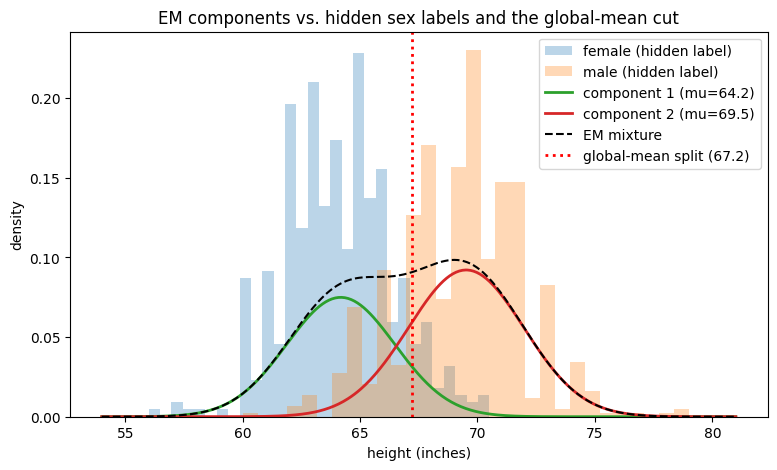

In [4]:
# Histogram colours = hidden SEX labels (used only for display); the curves are what EM learned from heights alone.
fig = plot_em_fit(x, mu, var, pi,
                  groups={"female (hidden label)": x[~is_male], "male (hidden label)": x[is_male]},
                  cut=cut, title="EM components vs. hidden sex labels and the global-mean cut")
fig.savefig("part1_fit.png", dpi=150, bbox_inches="tight")


**How to read this plot.** The coloured histograms show the hidden *sex* labels (female and male), which EM never sees. The solid curves are the two Gaussian components EM learned from the unlabeled heights alone (Component 1 = lower mean, Component 2 = higher mean), the dashed curve is their mixture, and the red dotted line is the global-mean split. The colours are not family roles (child vs. father) and not the two components; they are only a reference for checking how closely the learned components line up with the male and female height distributions.


**Answer: no, we should not just cut at the mean and average each pile.**

1. **The two curves overlap.** A hard cut puts every point on one side in one group with 100% certainty. A short man and a tall woman both sit near the cut, yet each would be assigned with full confidence. In this data, 230 of the 1,139 heights (20%) have a best posterior below 0.8, so EM itself is unsure about them, yet the cut labels every one with full certainty. EM instead gives *soft* assignments (e.g. 62% / 38% at 66 in), so points in the overlap are shared between components in proportion to how likely each is.
2. **Truncated piles give biased parameters.** Each pile only contains one side of its bell curve, so its mean is pushed away from the cut and its variance is shrunk (cut piles: variances ≈ 4.1 and 3.6; EM: 5.3 and 6.0). The true curves have tails that cross the cut; the piles throw those tails away.
3. **The global mean is not the boundary between the groups.** It is a weighted average of both groups, so it depends on how many points each group has. A boundary should be where the two *weighted* densities $\pi_1\mathcal N_1$ and $\pi_2\mathcal N_2$ are equal, which depends on both means, both variances and both weights. The cut forces equal-ish piles (π ≈ 0.505) even though EM finds 0.43 / 0.57.
4. **EM fits the data better.** Its log-likelihood is higher (-3046.99 vs. -3071.12) and it recovers the real male/female structure more often (84.7% vs. 82.3% agreement).
5. **EM is iterative because of a chicken-and-egg problem.** To estimate the parameters you need to know the group of every point; to know the groups you need the parameters. EM alternates: guess groups softly (E-step), then re-estimate the parameters using those soft weights (M-step). The log-likelihood never decreases, and we stop when it stops changing.

**Why the global-mean split can fail (the maths).** A split at the global mean assigns every observation to a fixed pile, which is only reliable when the two groups barely overlap, have similar variances and similar mixing proportions. When the distributions overlap, observations near the cut can belong to either group and the split misclassifies them. When the variances are unequal, the point where the two weighted densities $\pi_1\mathcal N_1(x)$ and $\pi_2\mathcal N_2(x)$ cross is not the global mean. When the mixing proportions differ, the global mean moves towards the larger group, so the cut is shifted away from the true boundary. EM instead assigns responsibilities $r_{ik}$ (probabilities that sum to 1 for each point), and then iteratively updates the means, variances and mixing coefficients with those responsibilities as weights, so overlapping points count partly toward both components.

**Honest note about this dataset.** The fitted components have means of about 64 in (Component 1) and 69.5 in (Component 2). These are closer to *female* (about 64.1) and *male* (about 69.2) heights than to "child" vs. "parent". The children are adults, so each child's height is similar to the parent of the same sex, and height alone cannot separate generations. We therefore call the components **Component 1 (lower mean)** and **Component 2 (higher mean)** and treat them as probabilistic height clusters, not as definitive demographic classes. The agreement scores above come from comparing the clusters with the hidden sex labels, which are aligned with the heights and tested under both possible component-to-label mappings.


### Classifying a test height (posterior probabilities)

Height 68.5 in (= 68.50 in):
  P(Component 1) = 0.1321
  P(Component 2) = 0.8679
  Sum of probabilities = 1.0000

  60 in: P(Component 1) = 0.996 | P(Component 2) = 0.004
  64 in: P(Component 1) = 0.910 | P(Component 2) = 0.090
  66 in: P(Component 1) = 0.624 | P(Component 2) = 0.376
  68 in: P(Component 1) = 0.199 | P(Component 2) = 0.801
  70 in: P(Component 1) = 0.033 | P(Component 2) = 0.967
  73 in: P(Component 1) = 0.001 | P(Component 2) = 0.999


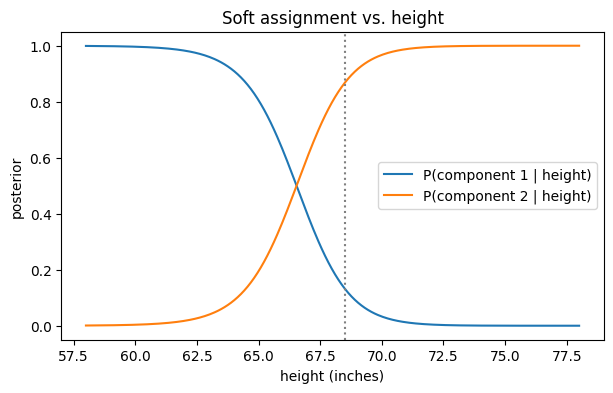

In [5]:
# NOTE: the Galton data is in INCHES. If the coach gives a height in cm, set unit="cm" (it is converted: cm / 2.54).
test_height, unit = 68.5, "in"          # <- replace with the height the coach gives
h_in, p = classify_height(test_height, mu, var, pi, unit=unit)
print(f"Height {test_height} {unit} (= {h_in:.2f} in):")
print(f"  P(Component 1) = {p[0]:.4f}")
print(f"  P(Component 2) = {p[1]:.4f}")
print(f"  Sum of probabilities = {p.sum():.4f}")
print()
for h in (60, 64, 66, 68, 70, 73):
    q = posterior(h, mu, var, pi)
    print(f"  {h} in: P(Component 1) = {q[0]:.3f} | P(Component 2) = {q[1]:.3f}")
fig = plot_posterior_curve(mu, var, pi, h=test_height)


## Part 2: Bayes' theorem on IMDb reviews
**Direction chosen: $P(\text{Positive}\mid\text{keyword})$** (we do *not* compute $P(\text{Negative}\mid\text{keyword})$).

$$P(\text{Pos}\mid w)=\frac{P(w\mid\text{Pos})\,P(\text{Pos})}{P(w)}$$

- **Prior** $P(\text{Pos})$ = positive reviews / all reviews
- **Likelihood** $P(w\mid\text{Pos})$ = positive reviews containing $w$ / positive reviews
- **Marginal** $P(w)$ = reviews containing $w$ / all reviews
- A review "contains" a word if it appears at least once (lower-cased, HTML `<br />` removed).

**Keywords.** Positive: *excellent, wonderful, amazing, superb*. Negative: *awful, waste, boring, worst*. We picked strongly valenced, unambiguous words. We deliberately avoided *great* and *bad* because they are common and often negated ("not bad", "not great"), which weakens them (checked: P(Pos|great) = 0.67, P(Pos|bad) = 0.25).
Only the standard library (`csv`, `re`) is used.

In [6]:
from bayes import load_reviews, keyword_stats, format_table

reviews = load_reviews("imdb.csv")
print("reviews loaded:", len(reviews))

positive_kw = ["excellent", "wonderful", "amazing", "superb"]
negative_kw = ["awful", "waste", "boring", "worst"]
stats = [keyword_stats(reviews, w) for w in positive_kw + negative_kw]
print(format_table(stats))

# The same four probabilities, spelled out for every keyword
for s in stats:
    print(f"\n{s['keyword']}:  Prior P(Positive) = {s['prior']:.4f} | Likelihood P(keyword|Positive) = {s['likelihood']:.4f} | "
          f"Marginal P(keyword) = {s['marginal']:.4f} | Posterior P(Positive|keyword) = {s['posterior']:.4f}")


reviews loaded: 50000
| Keyword | Prior P(Positive) | Likelihood P(kw|Positive) | Marginal P(kw) | Posterior P(Positive|kw) |
|---|---|---|---|---|
| excellent | 0.5000 | 0.1146 | 0.0710 | 0.8073 |
| wonderful | 0.5000 | 0.0902 | 0.0555 | 0.8120 |
| amazing | 0.5000 | 0.0671 | 0.0431 | 0.7783 |
| superb | 0.5000 | 0.0410 | 0.0240 | 0.8557 |
| awful | 0.5000 | 0.0112 | 0.0575 | 0.0977 |
| waste | 0.5000 | 0.0070 | 0.0507 | 0.0687 |
| boring | 0.5000 | 0.0236 | 0.0610 | 0.1938 |
| worst | 0.5000 | 0.0164 | 0.0886 | 0.0924 |

excellent:  Prior P(Positive) = 0.5000 | Likelihood P(keyword|Positive) = 0.1146 | Marginal P(keyword) = 0.0710 | Posterior P(Positive|keyword) = 0.8073

wonderful:  Prior P(Positive) = 0.5000 | Likelihood P(keyword|Positive) = 0.0902 | Marginal P(keyword) = 0.0555 | Posterior P(Positive|keyword) = 0.8120

amazing:  Prior P(Positive) = 0.5000 | Likelihood P(keyword|Positive) = 0.0671 | Marginal P(keyword) = 0.0431 | Posterior P(Positive|keyword) = 0.7783

superb:  Pr

In [7]:
# Sanity check: Bayes' formula must equal the directly counted P(Positive | keyword)
for s in stats:
    assert abs(s["posterior"] - s["direct"]) < 1e-12
    print(f"{s['keyword']:10s} appears in {s['n_kw']:5d} reviews | Bayes = {s['posterior']:.4f} | direct count = {s['direct']:.4f}")

excellent  appears in  3549 reviews | Bayes = 0.8073 | direct count = 0.8073
wonderful  appears in  2777 reviews | Bayes = 0.8120 | direct count = 0.8120
amazing    appears in  2156 reviews | Bayes = 0.7783 | direct count = 0.7783
superb     appears in  1199 reviews | Bayes = 0.8557 | direct count = 0.8557
awful      appears in  2875 reviews | Bayes = 0.0977 | direct count = 0.0977
waste      appears in  2533 reviews | Bayes = 0.0687 | direct count = 0.0687
boring     appears in  3049 reviews | Bayes = 0.1938 | direct count = 0.1938
worst      appears in  4428 reviews | Bayes = 0.0924 | direct count = 0.0924


**Reading the results.** The prior is 0.5 (the dataset is balanced: 25,000 positive and 25,000 negative reviews). A word is informative when its likelihood differs a lot from its marginal. For *superb*, P(w|Pos) = 0.041 while P(w) = 0.024, so seeing it lifts the probability of "positive" from 0.50 to 0.86. For *waste*, P(w|Pos) = 0.007 but P(w) = 0.051, so the probability of "positive" falls to 0.069. The negative keywords all give a low P(Positive|w), which is exactly what we expected from "negative" words. No single word is certain (the highest posterior is 0.856, for superb), so one keyword is evidence, not proof.

**Keyword selection and interpretation.** We selected four positive-sentiment keywords (*excellent*, *wonderful*, *amazing* and *superb*) and four negative-sentiment keywords (*awful*, *waste*, *boring* and *worst*). These words were chosen because they commonly express praise or dissatisfaction in movie reviews. However, a keyword does not guarantee the sentiment of an entire review. The posterior probabilities therefore describe the relationship between each keyword and positive reviews in our dataset, rather than proving that every review containing the word has that sentiment.

**Dataset and counting check.** `imdb.csv` is included in the submission. Every probability uses the same 50,000 reviews, and `load_reviews` stores each review's words as a *set*, so we count **reviews that contain the keyword**, not repeated occurrences inside one review. Prior, likelihood, marginal and posterior therefore all use the same review-level definitions, and the assertion above confirms Bayes' theorem equals direct counting.


## Part 3: Gradient descent by hand (matrix form)
**Model** (from the brief: $y=m_1x_1+m_2x_2+b$), written in matrix form as $\hat y = Xm + b$, i.e. $\hat y_i=m_1x_{i1}+m_2x_{i2}+b_i$ (b is a vector with one entry per data point, as given: $b=[1,1]$), with

$X=\begin{bmatrix}1&3\\4&10\end{bmatrix},\; y=\begin{bmatrix}5\\6\end{bmatrix},\; m_0=\begin{bmatrix}-1\\2\end{bmatrix},\; b_0=\begin{bmatrix}1\\1\end{bmatrix}$, and $n=2$.

The assignment gives no learning rate, so we use **$\alpha=0.01$**. (Stability check: the largest eigenvalue of $\frac2nX^TX$ is ≈126, so α must be below 2/126 ≈ 0.0159 for descent to be stable.)

**Model interpretation.** We implement the supplied model using matrix multiplication: $\hat{y}=Xm+b$. The parameter vector $m=[m_1,m_2]$ contains the feature coefficients, while $b=[b_1,b_2]$ contains one bias value for each of the two data points. This follows the assignment's specified initialization $b=[1,1]$. It differs from standard linear regression, which normally uses one shared scalar intercept.

**Cost:** $J=\frac1n(\hat y-y)^T(\hat y-y)$. Let $e=\hat y-y$.

**Chain rule.** $J=\frac1n e^Te,\quad e=Xm+b-y$

$$\frac{\partial J}{\partial m}=\underbrace{\frac{\partial J}{\partial e}}_{\frac2n e^T}\;\underbrace{\frac{\partial e}{\partial m}}_{X}\;\Rightarrow\;\frac{\partial J}{\partial m}=\frac2nX^Te$$
$$\frac{\partial J}{\partial b}=\underbrace{\frac{\partial J}{\partial e}}_{\frac2n e^T}\;\underbrace{\frac{\partial e}{\partial b}}_{I}\;\Rightarrow\;\frac{\partial J}{\partial b}=\frac2n e$$

**The same chain rule written element by element (no matrix shorthand).** $J=\frac1n\sum_i(\hat y_i-y_i)^2$. Then $\frac{\partial J}{\partial \hat y_i}=\frac2n e_i$, $\frac{\partial\hat y_i}{\partial m_j}=x_{ij}$, and $\frac{\partial\hat y_i}{\partial b_k}=1$ if $k=i$, else $0$. Therefore
$$\frac{\partial J}{\partial m_j}=\sum_i\frac{\partial J}{\partial\hat y_i}\frac{\partial\hat y_i}{\partial m_j}=\frac2n\sum_i e_i x_{ij}=\frac2n(X^Te)_j,\qquad \frac{\partial J}{\partial b_k}=\frac2n e_k$$

**Updates:** $m\leftarrow m-\alpha\frac{\partial J}{\partial m},\quad b\leftarrow b-\alpha\frac{\partial J}{\partial b}$. Three updates, one per group member.

In [8]:
import numpy as np
from gradient_descent import predict, mse, gradients, gradient_descent

X  = np.array([[1, 3], [4, 10]], dtype=float)
y  = np.array([5, 6], dtype=float)
m0 = np.array([-1, 2], dtype=float)
b0 = np.array([1, 1], dtype=float)
lr = 0.01

print("Initial predictions y_hat =", predict(X, m0, b0), "  error e = y_hat - y =", predict(X, m0, b0) - y, "  J =", mse(X, m0, b0, y))
m, b, hist3 = gradient_descent(X, y, m0, b0, lr, n_iter=3, verbose=True)

Initial predictions y_hat = [ 6. 17.]   error e = y_hat - y = [ 1. 11.]   J = 61.0
iter 1: y_hat_before=[ 6. 17.], grad_m=[ 45. 113.], grad_b=[ 1. 11.], m=[-1.45  0.87], b=[0.99 0.89], J=6.503300
iter 2: y_hat_before=[2.15 3.79], grad_m=[-11.69 -30.65], grad_b=[-2.85 -2.21], m=[-1.3331  1.1765], b=[1.0185 0.9121], J=2.497400
iter 3: y_hat_before=[3.2149 7.3447], grad_m=[3.5937 8.0917], grad_b=[-1.7851  1.3447], m=[-1.369037  1.095583], b=[1.036351 0.898653], J=2.164498


**Trend.** The error drops sharply and keeps falling: J goes 61 → 6.503 → 2.497 → 2.164, so every update moves in a direction that reduces the error. The first step is the biggest because the initial gradient (45, 113) is large. It overshoots: $m_2$ goes 2 → 0.87 and $m_1$ goes −1 → −1.45, and the next updates pull them back (m₂: 0.87 → 1.177 → 1.096; m₁: −1.45 → −1.333 → −1.369). The biases change much less (b₁: 1 → 0.99 → 1.019 → 1.036, b₂: 1 → 0.89 → 0.912 → 0.899). This back-and-forth in m is the sign of a step that is large along the steepest direction of the cost surface (largest eigenvalue ≈126), but α = 0.01 is still small enough that the error never goes up.

## Part 4: Gradient descent in code with SciPy
`derivative_of_equation(f, x0)` wraps `scipy.differentiate.derivative` and differentiates any single-variable equation. `numerical_gradients` applies it to $J$ for every parameter. The update loop in `gradient_descent` shows every step (predict, gradient, update m, update b, new error), and its `gradient_fn` argument lets us run it twice: once with SciPy's derivative computing every gradient, and once with our chain-rule matrix gradients. The two runs must agree.

In [9]:
from gradient_descent import derivative_of_equation, numerical_gradients, gradients

# 1) Requirement: a function that accepts an equation and computes its derivative (SciPy).
#    derivative_of_equation(equation, x0) = float(derivative(equation, x0).df)   (see gradient_descent.py)
f = lambda x: x**3 + 2*x
print("Derivative at x = 2:", round(derivative_of_equation(f, 2.0), 6), "(exact value 14)")

# 2) SciPy numerical gradient of J vs. our analytic matrix gradient at the starting point
gm_num, gb_num = numerical_gradients(X, m0, b0, y)
gm_ana, gb_ana = gradients(X, m0, b0, y)
print("dJ/dm  analytic", gm_ana, " scipy", gm_num.round(6))
print("dJ/db  analytic", gb_ana, " scipy", gb_num.round(6))


Derivative at x = 2: 14.0 (exact value 14)


dJ/dm  analytic [ 45. 113.]  scipy [ 45. 113.]
dJ/db  analytic [ 1. 11.]  scipy [ 1. 11.]


In [10]:
# Initial state
print("Initial predictions y_hat =", predict(X, m0, b0).round(4), "  initial MSE J =", round(mse(X, m0, b0, y), 4))

# Run A: every update uses the gradient computed by SciPy's derivative function
m_final, b_final, hist = gradient_descent(X, y, m0, b0, lr, n_iter=300, gradient_fn=numerical_gradients)
# Run B: every update uses our analytic chain-rule matrix gradient
m_ana, b_ana, hist_ana = gradient_descent(X, y, m0, b0, lr, n_iter=300)

# First three updates: gradients for m and b, then the updated m and b
for h in hist[1:4]:
    print(f"iter {h['iter']}: grad_m = {h['grad_m'].round(4)}, grad_b = {h['grad_b'].round(4)} -> m = {h['m'].round(4)}, b = {h['b'].round(4)}, J = {h['J']:.4f}")

print("\nSciPy-driven run == analytic run (all 300 iterations):",
      np.allclose([h["J"] for h in hist], [h["J"] for h in hist_ana]) and np.allclose(m_final, m_ana) and np.allclose(b_final, b_ana))
print("first 3 SciPy-driven updates match the manual calculations:", np.allclose(hist[3]["m"], m) and np.allclose(hist[3]["b"], b))
print("final m =", m_final.round(4), " final b =", b_final.round(4))
print("targets           y =", y)
print("final predictions y_hat =", predict(X, m_final, b_final).round(4), "  final MSE J =", round(hist[-1]["J"], 6))


Initial predictions y_hat = [ 6. 17.]   initial MSE J = 61.0


iter 1: grad_m = [ 45. 113.], grad_b = [ 1. 11.] -> m = [-1.45  0.87], b = [0.99 0.89], J = 6.5033
iter 2: grad_m = [-11.69 -30.65], grad_b = [-2.85 -2.21] -> m = [-1.3331  1.1765], b = [1.0185 0.9121], J = 2.4974
iter 3: grad_m = [3.5937 8.0917], grad_b = [-1.7851  1.3447] -> m = [-1.369   1.0956], b = [1.0364 0.8987], J = 2.1645

SciPy-driven run == analytic run (all 300 iterations): True
first 3 SciPy-driven updates match the manual calculations: True
final m = [-1.6794  1.2382]  final b = [2.8734 0.3618]
targets           y = [5. 6.]
final predictions y_hat = [4.9087 6.0268]   final MSE J = 0.004522


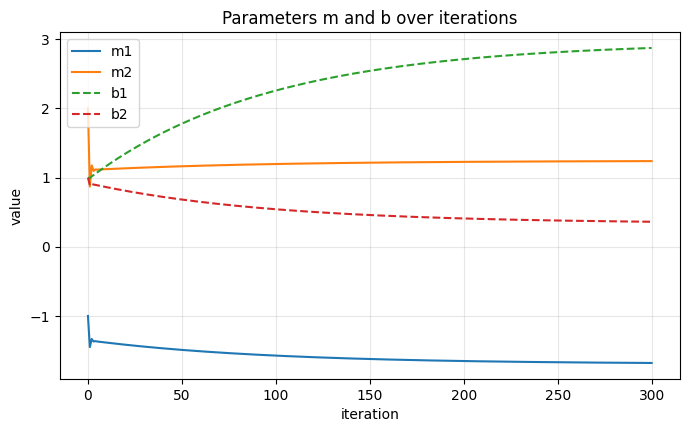

In [11]:
from plots import plot_parameters, plot_error
fig = plot_parameters(hist); fig.savefig("part4_params.png", dpi=150, bbox_inches="tight")

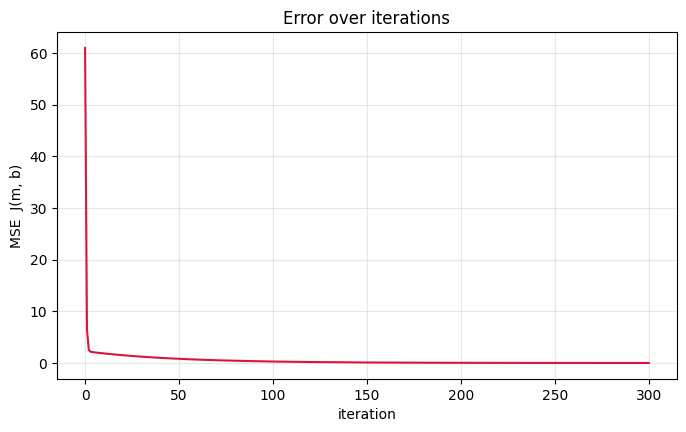

In [12]:
fig = plot_error(hist); fig.savefig("part4_error.png", dpi=150, bbox_inches="tight")

**Observations.** The error falls from 61 to about 0.005 after 300 iterations, and the predictions (4.91, 6.03) approach the targets (5, 6). The parameters change fastest in the first few iterations (steep part of the surface), then drift slowly. With only two data points and four parameters, many $(m,b)$ solve the problem exactly, so gradient descent moves toward the solution closest to the starting point rather than toward a single unique answer.